## Targeting Strategies
Aims to compare the effects of targeting the top 30% of customers using various strategies
1. Causal forest targeting
2. Random targeting
3. Spend-based targeting
4. Linear interaction model targeting
5. Treat everyone

### 1. Causal Forest Targeting

Run causal_forest.ipynb notebook if haven't

In [ ]:
%run causal_forest.ipynb

Imports and settings

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

RANDOM_STATE = 1213  # must match causal_forest.ipynb so the split is identical
BUDGET = 0.30  # share of customers the firm can target
N_BOOT = 500  # number of bootstrap replications

PROJECT_ROOT = Path.cwd().resolve().parent
DATA_PATH = next(p for p in [PROJECT_ROOT / "data" / "processed" / "retailhero_causal_forest_features.csv",
                             PROJECT_ROOT / "data" / "Processed" / "retailhero_causal_forest_features.csv"] if p.exists())
OUTPUT_DIR = PROJECT_ROOT / "data" / "output"
CATE_PATH = OUTPUT_DIR / "cf_cate_results.csv"

rng = np.random.default_rng(RANDOM_STATE)

Load data and rebuilt train / test set

In [2]:
df = pd.read_csv(DATA_PATH)
cate_results = pd.read_csv(CATE_PATH)

Y = df["target"].astype(int)
Z = df["treatment"].astype(int)
X = df.drop(columns=["target", "treatment", "client_id", "gender_U"], errors="ignore")

strata = Z.astype(str) + "_" + Y.astype(str)
X_train, X_test, Y_train, Y_test, Z_train, Z_test = train_test_split(
    X, Y, Z, test_size=0.3, random_state=RANDOM_STATE, stratify=strata)

# Check the rebuilt test set is the same customers, in the same order, as cf_cate_results.csv
test_ids = df.loc[X_test.index, "client_id"].to_numpy()
assert (test_ids == cate_results["client_id"].to_numpy()).all(), \
    "Test set does not match cf_cate_results.csv - rerun causal_forest.ipynb"
print(f"Test set verified: {len(test_ids):,} customers")

tau_hat = cate_results["cate_hat"].to_numpy()
y_te, z_te = Y_test.to_numpy(), Z_test.to_numpy()
n = len(y_te)

Test set verified: 60,012 customers


AIPW (Augmented Inverse Probability Weighting) score for RATE (Rank Average Treatment Effect)

In [3]:
def fit_mu(arm):
    m = RandomForestRegressor(n_estimators=100, min_samples_leaf=50,
                              random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_train[Z_train == arm], Y_train[Z_train == arm])
    return m.predict(X_test)

mu1, mu0 = fit_mu(1), fit_mu(0)
e = Z_train.mean()

gamma = (mu1 - mu0
         + z_te * (y_te - mu1) / e
         - (1 - z_te) * (y_te - mu0) / (1 - e))

ate = gamma.mean()
dim = y_te[z_te == 1].mean() - y_te[z_te == 0].mean()
print(f"ATE (AIPW):               {ate:.4f}")
print(f"ATE (difference in means): {dim:.4f}   <- should be very close")

ATE (AIPW):               0.0315
ATE (difference in means): 0.0332   <- should be very close


Rank customers by CATE and select top 30%

In [4]:
def rank_order(score, rng):
    """Indices sorted from highest to lowest score; ties broken at random."""
    return np.lexsort((rng.random(len(score)), -score))

k = int(round(BUDGET * n))
order = rank_order(tau_hat, rng)

ranked = cate_results.copy()
ranked["gamma"] = gamma
ranked["cf_rank"] = np.empty(n, dtype=int)
ranked.loc[order, "cf_rank"] = np.arange(1, n + 1)
ranked["cf_top30"] = ranked["cf_rank"] <= k
ranked = ranked.sort_values("cf_rank")
display(ranked.head(10))

top = order[:k]
t, c = z_te[top] == 1, z_te[top] == 0
print(f"Customers targeted:                        {k:,}")
print(f"Uplift per targeted customer (AIPW):       {gamma[top].mean():.4f}")
print(f"Uplift per targeted customer (diff. means): {y_te[top][t].mean() - y_te[top][c].mean():.4f}")
print(f"Incremental purchases (test set):          {gamma[top].sum():.1f}")

ranked.to_csv(OUTPUT_DIR / "cf_ranked_customers.csv", index=False)

,client_id,treatment,target,cate_hat,gamma,cf_rank,cf_top30
983,205a845a5b,0,0,0.408422,0.802524,1,True
4245,5c270e445b,1,1,0.403882,1.341736,2,True
24829,f0ecaaaf57,1,1,0.401735,1.382936,3,True
34826,eb7881a604,1,1,0.398252,1.290167,4,True
7380,56b9d0d410,0,0,0.391965,0.934066,5,True
4411,ff47ffe826,1,1,0.390174,1.386189,6,True
30594,ff793eeb4b,1,0,0.379794,-0.852751,7,True
5064,55ef8029e8,1,1,0.378613,1.046007,8,True
32984,96b5100a11,0,1,0.376278,-1.231750,9,True
29584,7ec9fedd4b,1,0,0.372631,-0.855970,10,True


Customers targeted:                        18,004
Uplift per targeted customer (AIPW):       0.0590
Uplift per targeted customer (diff. means): 0.0610
Incremental purchases (test set):          1061.7


Qini curve and AUQ

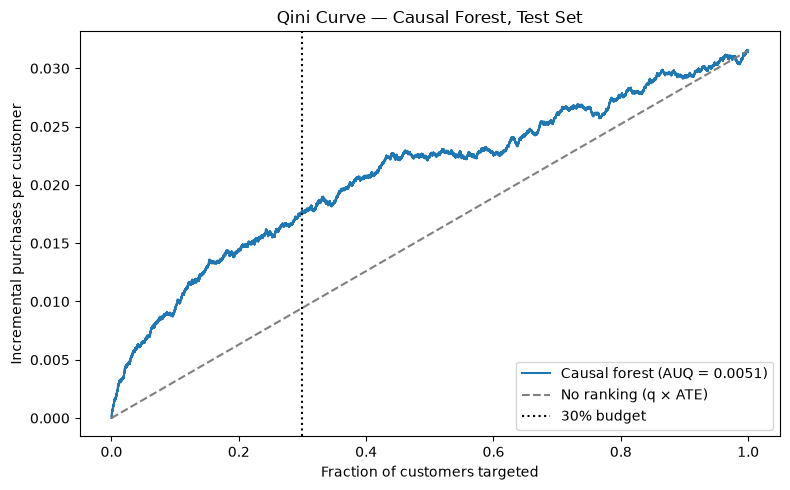

In [5]:
def qini_curve(score, gamma, rng):
    m = len(gamma)
    q = np.arange(1, m + 1) / m
    Q = np.cumsum(gamma[rank_order(score, rng)]) / m
    return q, Q

def auq(score, gamma, rng):
    q, Q = qini_curve(score, gamma, rng)
    return np.mean(Q - q * gamma.mean())

def value_at(score, gamma, rng, budget=BUDGET):
    """Q(budget): incremental purchases per customer in the population at the cutoff."""
    m = len(gamma)
    return gamma[rank_order(score, rng)[:int(round(budget * m))]].sum() / m

q, Q = qini_curve(tau_hat, gamma, rng)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(q, Q, label=f"Causal forest (AUQ = {auq(tau_hat, gamma, rng):.4f})")
ax.plot([0, 1], [0, ate], linestyle="--", color="grey", label="No ranking (q × ATE)")
ax.axvline(BUDGET, linestyle=":", color="black", label=f"{BUDGET:.0%} budget")
ax.set_xlabel("Fraction of customers targeted")
ax.set_ylabel("Incremental purchases per customer")
ax.set_title("Qini Curve — Causal Forest, Test Set")
ax.legend()
plt.tight_layout()
plt.show()

Bootstrap for standard error and confidence intervals

In [6]:
def stats_on(idx, rng):
    g, s = gamma[idx], tau_hat[idx]
    return {
        "ATE": g.mean(),
        "AUQ (Qini coefficient)": auq(s, g, rng),
        "Q(30%)": value_at(s, g, rng),
        "Uplift per targeted customer": value_at(s, g, rng) / BUDGET,
    }

point = stats_on(np.arange(n), rng)
boot = pd.DataFrame([stats_on(rng.integers(0, n, n), rng) for _ in range(N_BOOT)])

results = pd.DataFrame({
    "estimate": pd.Series(point),
    "boot_se": boot.std(ddof=1),
    "ci_lower": boot.quantile(0.025),
    "ci_upper": boot.quantile(0.975),
})
results["z"] = results["estimate"] / results["boot_se"]
display(results.round(4))

results.to_csv(OUTPUT_DIR / "cf_targeting_results.csv")
print(f"Saved to {OUTPUT_DIR / 'cf_targeting_results.csv'}")

,estimate,boot_se,ci_lower,ci_upper,z
ATE,0.0315,0.0034,0.0254,0.0383,9.1988
AUQ (Qini coefficient),0.0051,0.0010,0.0030,0.0070,4.9580
Q(30%),0.0177,0.0020,0.0137,0.0216,8.7694
Uplift per targeted customer,0.0590,0.0067,0.0456,0.0721,8.7694


Saved to /Users/shannonkwok/Desktop/DSE4101/DSE4101-CausalForest-Grp2/data/output/cf_targeting_results.csv


### 5. Treating Everyone

In [7]:
everyone_summary = pd.Series({
    "Customers targeted": n,
    "Uplift per targeted customer (AIPW)": gamma.mean(),
    "Uplift per targeted customer (diff. means)": y_te[z_te == 1].mean() - y_te[z_te == 0].mean(),
    "Incremental purchases (test set)": gamma.sum(),
})
display(everyone_summary.round(4))

Customers targeted                            60012.0000
Uplift per targeted customer (AIPW)               0.0315
Uplift per targeted customer (diff. means)        0.0332
Incremental purchases (test set)               1891.8914
dtype: float64

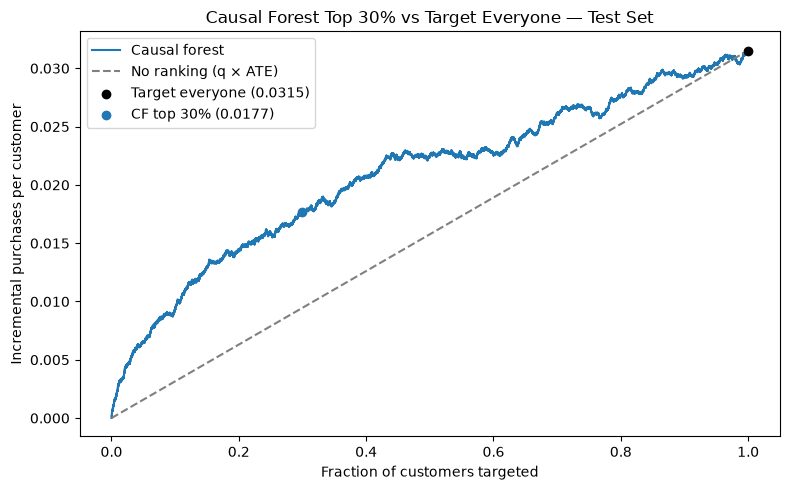

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
q, Q = qini_curve(tau_hat, gamma, rng)
ax.plot(q, Q, label="Causal forest")
ax.plot([0, 1], [0, ate], linestyle="--", color="grey", label="No ranking (q × ATE)")
ax.scatter([1], [ate], color="black", zorder=3, label=f"Target everyone ({ate:.4f})")
ax.scatter([BUDGET], [value_at(tau_hat, gamma, rng)], color="tab:blue", zorder=3,
           label=f"CF top {BUDGET:.0%} ({value_at(tau_hat, gamma, rng):.4f})")
ax.set_xlabel("Fraction of customers targeted")
ax.set_ylabel("Incremental purchases per customer")
ax.set_title("Causal Forest Top 30% vs Target Everyone — Test Set")
ax.legend()
plt.tight_layout()
plt.show()

Bootstrap

In [9]:
def stats_everyone(idx, rng):
    g, s = gamma[idx], tau_hat[idx]
    ate_b = g.mean()
    q30 = value_at(s, g, rng)
    return {
        "Everyone: uplift per targeted customer (= ATE)": ate_b,
        "Everyone: Q(100%)": ate_b,
        "CF: uplift per targeted customer": q30 / BUDGET,
        "Uplift per targeted: CF - everyone": q30 / BUDGET - ate_b,
        "Share of total uplift captured by CF top 30%": q30 / ate_b,
    }

point_ev = stats_everyone(np.arange(n), rng)
boot_ev = pd.DataFrame([stats_everyone(rng.integers(0, n, n), rng) for _ in range(N_BOOT)])

results_everyone = pd.DataFrame({
    "estimate": pd.Series(point_ev),
    "boot_se": boot_ev.std(ddof=1),
    "ci_lower": boot_ev.quantile(0.025),
    "ci_upper": boot_ev.quantile(0.975),
})
results_everyone["z"] = results_everyone["estimate"] / results_everyone["boot_se"]
display(results_everyone.round(4))

results_everyone.to_csv(OUTPUT_DIR / "everyone_targeting_results.csv")
print(f"Saved to {OUTPUT_DIR / 'everyone_targeting_results.csv'}")

,estimate,boot_se,ci_lower,ci_upper,z
Everyone: uplift per targeted customer (= ATE),0.0315,0.0034,0.0246,0.0379,9.2962
Everyone: Q(100%),0.0315,0.0034,0.0246,0.0379,9.2962
CF: uplift per targeted customer,0.0590,0.0069,0.0451,0.0727,8.5588
Uplift per targeted: CF - everyone,0.0274,0.0056,0.0175,0.0391,4.8900
Share of total uplift captured by CF top 30%,0.5612,0.0601,0.4685,0.6973,9.3452


Saved to /Users/shannonkwok/Desktop/DSE4101/DSE4101-CausalForest-Grp2/data/output/everyone_targeting_results.csv
